
# DLinear Model for Long-Horizon Forecasting

**Course:** ELE680 – Deep Neural Networks  
**Group:** Group 2  
**Dataset:** ETTh1 (Electricity Transformer Temperature)  
**Date:** 20 October 2026

## Objective

Implement the DLinear (Decomposition-Linear) model for long-horizon time series forecasting.

### Experimental Setup
- Input sequence length: 96 hours
- Prediction horizon: 96 hours
- Input features: 7
- Target variable: Oil Temperature (OT)
- Evaluation metrics: MSE and MAE

### Research Question

Does increasing model complexity improve long-horizon forecasting performance?

We will compare:
1. Persistence Baseline
2. DLinear
3. Transformer

In [2]:

# Step 1: Import libraries and configure device

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

# Select the assigned GPU if available
device = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)

print("PyTorch version:", torch.__version__)
print("Selected device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.5.1+cu118
Selected device: cuda:0
GPU: Tesla P100-PCIE-12GB



## 2. Load Preprocessed ETTh1 Data

Load the previously prepared ETTh1 dataset containing chronological training, validation, and test splits.

The data has already been standardized and converted into 96-hour input and prediction windows.

We will inspect the tensor shapes before implementing the DLinear architecture.


In [3]:

# Step 2: Load preprocessed ETTh1 tensors

data_path = "processed_data/ETTh1_preprocessed.pt"

data = torch.load(
    data_path,
    map_location="cpu",
    weights_only=True
)

print("Data loaded successfully!")
print("\nAvailable keys:", list(data.keys()))

# Inspect the saved tensor shapes
for key, value in data.items():
    if isinstance(value, torch.Tensor):
        print(f"{key}: {value.shape}")
    else:
        print(f"{key}: {type(value).__name__}")


Data loaded successfully!

Available keys: ['X_train', 'y_train', 'X_val', 'y_val', 'X_test', 'y_test', 'feature_cols', 'target_index', 'input_len', 'pred_len', 'ot_mean', 'ot_std']
X_train: torch.Size([8449, 96, 7])
y_train: torch.Size([8449, 96])
X_val: torch.Size([2785, 96, 7])
y_val: torch.Size([2785, 96])
X_test: torch.Size([2785, 96, 7])
y_test: torch.Size([2785, 96])
feature_cols: list
target_index: int
input_len: int
pred_len: int
ot_mean: float
ot_std: float



## 3. Verify Dataset Configuration

Inspect the saved dataset metadata to confirm the input features, target variable, sequence lengths, and normalization parameters.

This ensures that the DLinear model uses the same experimental configuration as the Persistence baseline.

In [4]:

# Step 3: Verify dataset metadata

print("Input features:", data["feature_cols"])
print("Target index:", data["target_index"])

print("Input sequence length:", data["input_len"])
print("Prediction length:", data["pred_len"])

print("OT mean:", data["ot_mean"])
print("OT standard deviation:", data["ot_std"])

# Verify target variable
target_name = data["feature_cols"][data["target_index"]]

print("\nPrediction target:", target_name)

# Confirm expected configuration
assert data["input_len"] == 96
assert data["pred_len"] == 96
assert len(data["feature_cols"]) == 7
assert target_name == "OT"

print("\nDataset configuration verified successfully!")

Input features: ['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']
Target index: 6
Input sequence length: 96
Prediction length: 96
OT mean: 17.1282616982271
OT standard deviation: 9.176491024944333

Prediction target: OT

Dataset configuration verified successfully!



## 4. DLinear Architecture

### 4.1 Moving Average Decomposition

DLinear separates the input time series into a trend component and a residual (seasonal) component.

The trend is estimated using a moving average with a kernel size of 25.

The residual component is calculated as:

Residual = Original Series - Trend

Both components will later be processed by separate linear forecasting layers.

In [5]:

# Step 4: Implement moving average decomposition

class MovingAverage(nn.Module):
    def __init__(self, kernel_size):
        super().__init__()

        self.kernel_size = kernel_size

        self.avg = nn.AvgPool1d(
            kernel_size=kernel_size,
            stride=1,
            padding=0
        )

    def forward(self, x):
        # x shape: [batch, sequence_length, features]

        # Repeat boundary values to preserve sequence length
        pad_size = (self.kernel_size - 1) // 2

        front = x[:, 0:1, :].repeat(1, pad_size, 1)
        end = x[:, -1:, :].repeat(1, pad_size, 1)

        x_padded = torch.cat([front, x, end], dim=1)

        # AvgPool1d expects [batch, features, sequence_length]
        x_padded = x_padded.permute(0, 2, 1)

        moving_mean = self.avg(x_padded)

        # Return to [batch, sequence_length, features]
        moving_mean = moving_mean.permute(0, 2, 1)

        return moving_mean


class SeriesDecomposition(nn.Module):
    def __init__(self, kernel_size):
        super().__init__()

        self.moving_avg = MovingAverage(kernel_size)

    def forward(self, x):
        trend = self.moving_avg(x)
        seasonal = x - trend

        return seasonal, trend


print("Moving average and decomposition classes created successfully!")


Moving average and decomposition classes created successfully!



### 4.2 Test and Visualize Series Decomposition

Apply the moving-average decomposition to a sample from the ETTh1 training dataset.

Visualize the original oil temperature series, estimated trend, and residual component to verify that the decomposition works correctly.

Original shape: torch.Size([1, 96, 7])
Trend shape: torch.Size([1, 96, 7])
Seasonal shape: torch.Size([1, 96, 7])
Reconstruction correct: True


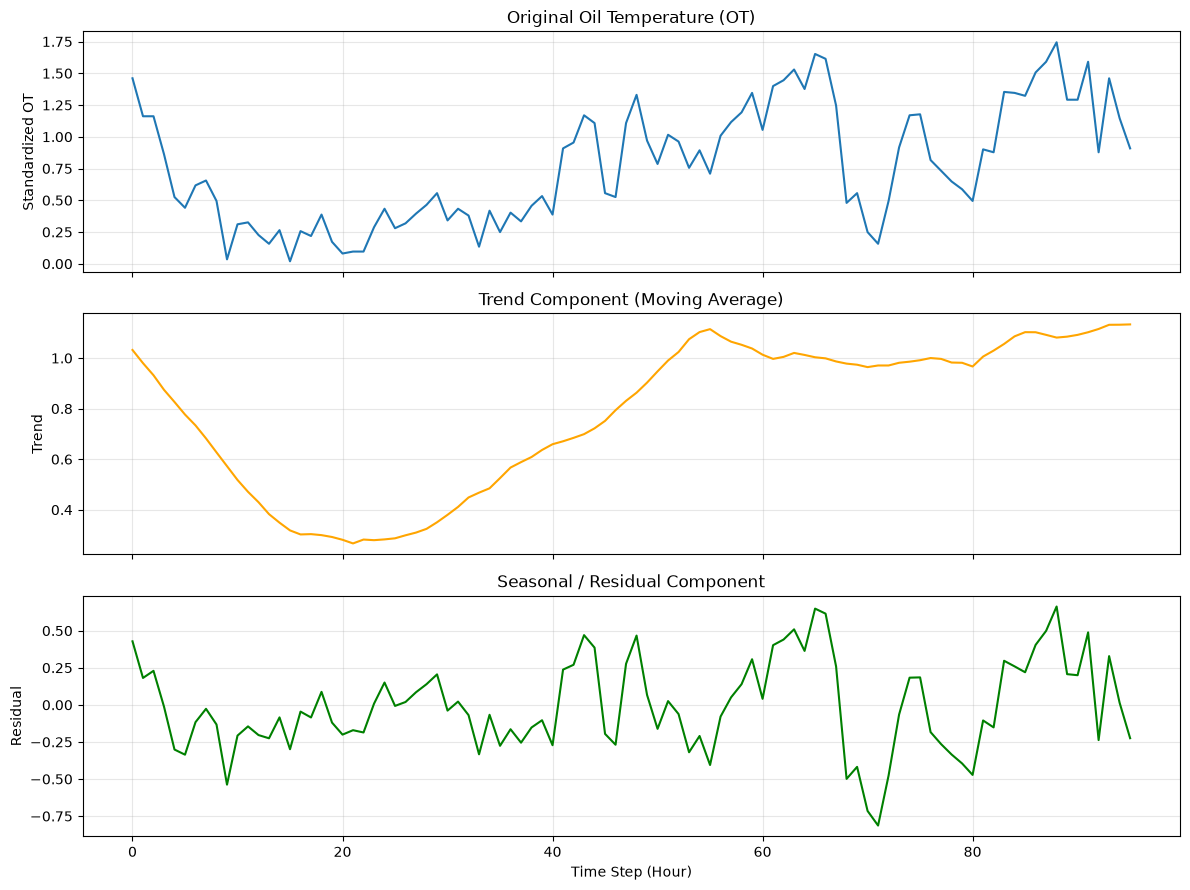

In [6]:

# Step 5: Test and visualize series decomposition

# Initialize decomposition with a 25-hour moving average
decomposition = SeriesDecomposition(kernel_size=25)

# Select the first training sample
sample = data["X_train"][0:1]

# Apply decomposition
with torch.no_grad():
    seasonal, trend = decomposition(sample)

# Extract the OT channel
target_index = data["target_index"]

original_ot = sample[0, :, target_index].numpy()
trend_ot = trend[0, :, target_index].numpy()
seasonal_ot = seasonal[0, :, target_index].numpy()

# Verify shapes and reconstruction
print("Original shape:", sample.shape)
print("Trend shape:", trend.shape)
print("Seasonal shape:", seasonal.shape)

reconstructed = trend + seasonal
print(
    "Reconstruction correct:",
    torch.allclose(sample, reconstructed, atol=1e-6)
)

# Plot decomposition
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

axes[0].plot(original_ot)
axes[0].set_title("Original Oil Temperature (OT)")
axes[0].set_ylabel("Standardized OT")

axes[1].plot(trend_ot, color="orange")
axes[1].set_title("Trend Component (Moving Average)")
axes[1].set_ylabel("Trend")

axes[2].plot(seasonal_ot, color="green")
axes[2].set_title("Seasonal / Residual Component")
axes[2].set_ylabel("Residual")
axes[2].set_xlabel("Time Step (Hour)")

for ax in axes:
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()



### 4.3 DLinear Forecasting Model

Implement the DLinear architecture using two learnable linear layers:

- Seasonal Linear Layer: Forecasts the residual component.
- Trend Linear Layer: Forecasts the trend component.

Each linear layer maps 96 historical time steps to 96 future time steps.

The two predictions are added together to obtain the final forecast.

We use the channel-independent DLinear variant and select the OT channel as the prediction target.

In [7]:

# Step 6: Implement the complete DLinear model

class DLinear(nn.Module):
    def __init__(self, input_len, pred_len, target_index,
                 kernel_size=25):
        super().__init__()

        self.input_len = input_len
        self.pred_len = pred_len
        self.target_index = target_index

        # Decompose the input into seasonal and trend components
        self.decomposition = SeriesDecomposition(kernel_size)

        # Learnable forecasting layers
        self.linear_seasonal = nn.Linear(input_len, pred_len)
        self.linear_trend = nn.Linear(input_len, pred_len)

        # Initialize weights with a simple averaging pattern
        nn.init.constant_(
            self.linear_seasonal.weight, 1.0 / input_len
        )
        nn.init.constant_(
            self.linear_trend.weight, 1.0 / input_len
        )

        nn.init.zeros_(self.linear_seasonal.bias)
        nn.init.zeros_(self.linear_trend.bias)

    def forward(self, x):
        # Input: [batch, 96, 7]

        seasonal, trend = self.decomposition(x)

        # Linear layers operate on the final dimension
        # Change shape to [batch, features, 96]
        seasonal = seasonal.permute(0, 2, 1)
        trend = trend.permute(0, 2, 1)

        # Forecast 96 future time steps
        seasonal_output = self.linear_seasonal(seasonal)
        trend_output = self.linear_trend(trend)

        # Combine predictions
        output = seasonal_output + trend_output

        # Select the OT channel
        output = output[:, self.target_index, :]

        # Final shape: [batch, 96]
        return output


print("DLinear model class created successfully!")


DLinear model class created successfully!



### 4.4 Initialize and Test the DLinear Model

Initialize the DLinear model using the ETTh1 dataset configuration.

Verify:
- Model architecture
- Number of trainable parameters
- Input and output tensor shapes
- Compatibility with the prediction target

A forward pass will be performed before training to ensure that the model produces 96 future OT predictions for each input sample.

In [8]:

# Step 7: Initialize and test the DLinear model

# Set random seed for reproducibility
torch.manual_seed(42)

# Initialize model
model = DLinear(
    input_len=data["input_len"],
    pred_len=data["pred_len"],
    target_index=data["target_index"],
    kernel_size=25
)

# Move model to selected device
model = model.to(device)

# Display model architecture
print("DLinear Model Architecture:")
print(model)

# Count trainable parameters
total_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("\nTotal trainable parameters:", total_params)

# Select a small batch of 4 training samples
X_sample = data["X_train"][:4].to(device)
y_sample = data["y_train"][:4].to(device)

# Test forward pass without training
model.eval()

with torch.no_grad():
    predictions = model(X_sample)

print("\nInput shape:", X_sample.shape)
print("Target shape:", y_sample.shape)
print("Prediction shape:", predictions.shape)

# Verify output shape
assert predictions.shape == y_sample.shape

print("\nDLinear forward pass successful!")


DLinear Model Architecture:
DLinear(
  (decomposition): SeriesDecomposition(
    (moving_avg): MovingAverage(
      (avg): AvgPool1d(kernel_size=(25,), stride=(1,), padding=(0,))
    )
  )
  (linear_seasonal): Linear(in_features=96, out_features=96, bias=True)
  (linear_trend): Linear(in_features=96, out_features=96, bias=True)
)

Total trainable parameters: 18624

Input shape: torch.Size([4, 96, 7])
Target shape: torch.Size([4, 96])
Prediction shape: torch.Size([4, 96])

DLinear forward pass successful!



## 5. Prepare DataLoaders for Model Training

Create PyTorch DataLoaders for the training, validation, and test datasets.

Configuration:
- Batch size: 32
- Training data: Shuffled
- Validation data: Not shuffled
- Test data: Not shuffled

The DataLoaders allow the model to process data in batches rather than loading the entire dataset onto the GPU.

The test dataset will be reserved for final evaluation after model selection.

In [9]:

# Step 8: Create PyTorch DataLoaders

from torch.utils.data import TensorDataset, DataLoader

# Set batch size
batch_size = 32

# Create datasets
train_dataset = TensorDataset(
    data["X_train"], data["y_train"]
)

val_dataset = TensorDataset(
    data["X_val"], data["y_val"]
)

test_dataset = TensorDataset(
    data["X_test"], data["y_test"]
)

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

# Display dataset information
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))

print("\nTraining batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

# Inspect one training batch
X_batch, y_batch = next(iter(train_loader))

print("\nInput batch shape:", X_batch.shape)
print("Target batch shape:", y_batch.shape)

print("\nDataLoaders created successfully!")


Training samples: 8449
Validation samples: 2785
Test samples: 2785

Training batches: 265
Validation batches: 88
Test batches: 88

Input batch shape: torch.Size([32, 96, 7])
Target batch shape: torch.Size([32, 96])

DataLoaders created successfully!



## 6. Configure Model Training

Configure the loss function, optimizer, and training hyperparameters for the DLinear model.

### Training Configuration

- Loss Function: Mean Squared Error (MSE)
- Optimizer: Adam
- Learning Rate: 0.001
- Batch Size: 32
- Maximum Epochs: 30
- Early Stopping Patience: 5
- Device: GPU 0 (CUDA)

The model will minimize MSE during training.

Validation loss will be monitored to select the best model and prevent overfitting.

The test dataset will remain unused during training and model selection.

In [10]:

# Step 9: Configure training settings

import torch.optim as optim

# Loss function
criterion = nn.MSELoss()

# Optimizer
learning_rate = 0.001

optimizer = optim.Adam(
    model.parameters(),
    lr=learning_rate
)

# Training hyperparameters
num_epochs = 30
patience = 5

# Store training history
train_losses = []
val_losses = []

# Early stopping variables
best_val_loss = float("inf")
epochs_without_improvement = 0

print("Training configuration:")
print("Loss function:", criterion)
print("Optimizer: Adam")
print("Learning rate:", learning_rate)
print("Maximum epochs:", num_epochs)
print("Early stopping patience:", patience)
print("Batch size:", batch_size)
print("Device:", device)

print("\nTraining configuration completed successfully!")


Training configuration:
Loss function: MSELoss()
Optimizer: Adam
Learning rate: 0.001
Maximum epochs: 30
Early stopping patience: 5
Batch size: 32
Device: cuda:0

Training configuration completed successfully!



## 7. Model Training and Validation

Implement the training and validation procedures for the DLinear model.

### Training Procedure

For each training batch:
1. Transfer the input and target tensors to the selected device.
2. Generate predictions using DLinear.
3. Calculate Mean Squared Error (MSE).
4. Compute gradients using backpropagation.
5. Update the model parameters using Adam.

### Validation Procedure

Evaluate the model on the validation dataset without updating model parameters.

The validation MSE will be used to monitor generalization performance, select the best model checkpoint, and determine when to stop training.

The test dataset will not be used during training or model selection.

In [11]:

# Step 10: Define training and validation functions

def train_one_epoch(model, loader, criterion, optimizer, device):

    # Enable training mode
    model.train()

    total_loss = 0.0
    total_samples = 0

    for X_batch, y_batch in loader:

        # Move batch to GPU
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        predictions = model(X_batch)

        # Calculate loss
        loss = criterion(predictions, y_batch)

        # Backpropagation
        loss.backward()

        # Update model parameters
        optimizer.step()

        # Accumulate sample-weighted loss
        batch_size_actual = X_batch.size(0)
        total_loss += loss.item() * batch_size_actual
        total_samples += batch_size_actual

    return total_loss / total_samples


def validate_one_epoch(model, loader, criterion, device):

    # Enable evaluation mode
    model.eval()

    total_loss = 0.0
    total_samples = 0

    # Disable gradient calculations
    with torch.no_grad():

        for X_batch, y_batch in loader:

            # Move batch to GPU
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            # Forward pass
            predictions = model(X_batch)

            # Calculate loss
            loss = criterion(predictions, y_batch)

            # Accumulate sample-weighted loss
            batch_size_actual = X_batch.size(0)
            total_loss += loss.item() * batch_size_actual
            total_samples += batch_size_actual

    return total_loss / total_samples


print("Training and validation functions created successfully!")


Training and validation functions created successfully!



### 7.1 One-Batch Training Test

Perform a small training test using one batch of ETTh1 training data.

This test verifies that:
- The forward pass produces valid predictions.
- The loss function calculates MSE correctly.
- Backpropagation computes gradients.
- The optimizer updates the model parameters.

The test is performed on a separate temporary model to avoid affecting the main DLinear model before full training.

In [12]:

# Step 11: Test one training batch using a temporary model

# Use CPU for this small test
test_device = torch.device("cpu")

# Create a separate temporary DLinear model
test_model = DLinear(
    input_len=data["input_len"],
    pred_len=data["pred_len"],
    target_index=data["target_index"],
    kernel_size=25
).to(test_device)

# Temporary optimizer
test_optimizer = optim.Adam(
    test_model.parameters(),
    lr=learning_rate
)

# Get one training batch
X_batch, y_batch = next(iter(train_loader))

X_batch = X_batch.to(test_device)
y_batch = y_batch.to(test_device)

# Enable training mode
test_model.train()

# Clear gradients
test_optimizer.zero_grad()

# Forward pass
predictions = test_model(X_batch)

# Calculate loss before update
loss = criterion(predictions, y_batch)

print("Initial batch MSE:", loss.item())

# Backpropagation
loss.backward()

# Update model parameters
test_optimizer.step()

# Calculate loss after update on the same batch
test_model.eval()

with torch.no_grad():
    updated_predictions = test_model(X_batch)
    updated_loss = criterion(updated_predictions, y_batch)

print("Batch MSE after one update:", updated_loss.item())

print("\nOne-batch training test completed successfully!")


Initial batch MSE: 0.19289708137512207
Batch MSE after one update: 0.18087129294872284

One-batch training test completed successfully!



## 8. Full DLinear Training

Train the DLinear model using the ETTh1 training dataset.

### Training Strategy

- Maximum epochs: 30
- Optimizer: Adam
- Learning rate: 0.001
- Loss function: Mean Squared Error (MSE)
- Early stopping patience: 5

### Model Selection

After each epoch, evaluate the model on the validation dataset.

Save the model checkpoint whenever validation MSE improves.

Stop training when validation MSE fails to improve for five consecutive epochs.

The best model will be selected using validation performance only. The test dataset remains reserved for final evaluation.

In [30]:

# Step 12: Define the full DLinear training procedure

import os
import time

def train_dlinear(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    device,
    num_epochs=30,
    patience=5,
    checkpoint_path="saved_models/DLinear_ETTh1_best.pt"
):

    os.makedirs("saved_models", exist_ok=True)

    train_losses = []
    val_losses = []

    best_val_loss = float("inf")
    epochs_without_improvement = 0

    start_time = time.time()

    for epoch in range(num_epochs):

        # Train for one epoch
        train_loss = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
            device
        )

        # Evaluate on validation data
        val_loss = validate_one_epoch(
            model,
            val_loader,
            criterion,
            device
        )

        # Save loss history
        train_losses.append(train_loss)
        val_losses.append(val_loss)

        print(
            f"Epoch [{epoch+1}/{num_epochs}] "
            f"Train MSE: {train_loss:.6f} | "
            f"Val MSE: {val_loss:.6f}"
        )

        # Save best model based on validation MSE
        if val_loss < best_val_loss:

            best_val_loss = val_loss
            epochs_without_improvement = 0

            torch.save(
                model.state_dict(),
                checkpoint_path
            )

            print("  Best model saved!")

        else:
            epochs_without_improvement += 1

        # Early stopping
        if epochs_without_improvement >= patience:
            print("\nEarly stopping triggered.")
            break

    training_time = time.time() - start_time

    print("\nTraining completed!")
    print(f"Best validation MSE: {best_val_loss:.6f}")
    print(f"Training time: {training_time:.2f} seconds")
    print(f"Best model saved to: {checkpoint_path}")

    return train_losses, val_losses, best_val_loss


print("Full DLinear training function created successfully!")


Full DLinear training function created successfully!



### 8.1 Execute DLinear Training

Train the DLinear model on GPU 0 using the ETTh1 training dataset.

The model will train for a maximum of 30 epochs, with early stopping based on validation MSE.

The best-performing model will be saved for final evaluation.

In [14]:

# Step 13: Execute DLinear training on GPU 0
# Run ONLY when GPU 0 is available and coordinated with Group 1

training_device = torch.device("cuda:0")

# Ensure the model is on the assigned GPU
model = model.to(training_device)

# Initialize optimizer for the training run
optimizer = optim.Adam(
    model.parameters(),
    lr=learning_rate
)

# Train DLinear
train_losses, val_losses, best_val_loss = train_dlinear(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    device=training_device,
    num_epochs=num_epochs,
    patience=patience
)

Epoch [1/30] Train MSE: 0.171095 | Val MSE: 0.097922
  Best model saved!
Epoch [2/30] Train MSE: 0.163936 | Val MSE: 0.096711
  Best model saved!
Epoch [3/30] Train MSE: 0.163144 | Val MSE: 0.097406
Epoch [4/30] Train MSE: 0.163963 | Val MSE: 0.098705
Epoch [5/30] Train MSE: 0.162185 | Val MSE: 0.097267
Epoch [6/30] Train MSE: 0.164286 | Val MSE: 0.097275
Epoch [7/30] Train MSE: 0.162630 | Val MSE: 0.097721

Early stopping triggered.

Training completed!
Best validation MSE: 0.096711
Training time: 6.24 seconds
Best model saved to: saved_models/DLinear_ETTh1_best.pt


In [15]:
# Step 14: Load the best DLinear checkpoint

checkpoint_path = "saved_models/DLinear_ETTh1_best.pt"

model.load_state_dict(
    torch.load(
        checkpoint_path,
        map_location=training_device,
        weights_only=True
    )
)

model.eval()

print("Best DLinear model loaded successfully!")
print("Device:", next(model.parameters()).device)

Best DLinear model loaded successfully!
Device: cuda:0


In [16]:
# Step 15: Evaluate DLinear using MSE and MAE

def evaluate_dlinear(model, data_loader, device):
    model.eval()

    total_squared_error = 0.0
    total_absolute_error = 0.0
    total_values = 0

    with torch.no_grad():
        for X_batch, y_batch in data_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            # Generate 96-hour forecasts
            predictions = model(X_batch)

            # Accumulate errors over all predicted values
            total_squared_error += torch.sum(
                (predictions - y_batch) ** 2
            ).item()

            total_absolute_error += torch.sum(
                torch.abs(predictions - y_batch)
            ).item()

            total_values += y_batch.numel()

    mse = total_squared_error / total_values
    mae = total_absolute_error / total_values

    return mse, mae


# Evaluate the best checkpoint
dlinear_val_mse, dlinear_val_mae = evaluate_dlinear(
    model, val_loader, training_device
)

dlinear_test_mse, dlinear_test_mae = evaluate_dlinear(
    model, test_loader, training_device
)

print("DLinear Evaluation Results")
print("-" * 35)
print(f"Validation MSE: {dlinear_val_mse:.6f}")
print(f"Validation MAE: {dlinear_val_mae:.6f}")
print(f"Test MSE:       {dlinear_test_mse:.6f}")
print(f"Test MAE:       {dlinear_test_mae:.6f}")

DLinear Evaluation Results
-----------------------------------
Validation MSE: 0.096711
Validation MAE: 0.243047
Test MSE:       0.071206
Test MAE:       0.197362


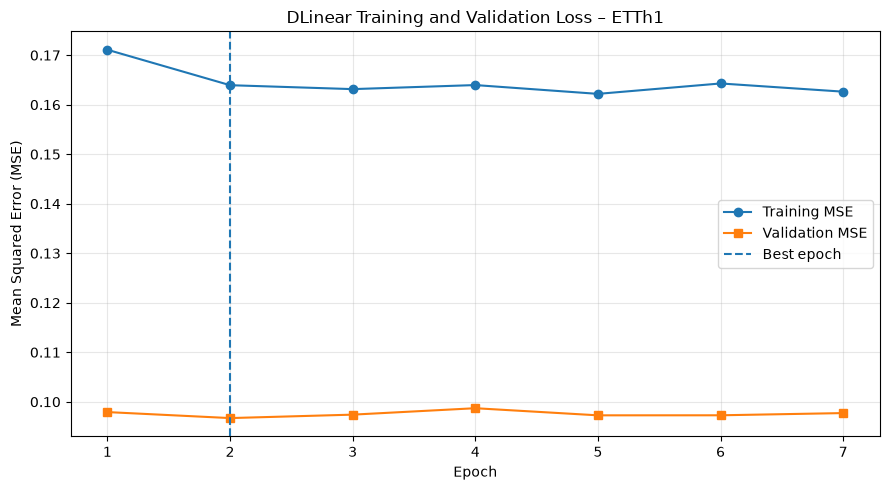

Best epoch: 2
Figure saved to figures/04_DLinear_Training_Loss.png


In [17]:
# Step 16: Plot DLinear training and validation losses

from pathlib import Path

figures_dir = Path("figures")
figures_dir.mkdir(exist_ok=True)

epochs = range(1, len(train_losses) + 1)

plt.figure(figsize=(9, 5))

plt.plot(
    epochs,
    train_losses,
    marker="o",
    label="Training MSE"
)

plt.plot(
    epochs,
    val_losses,
    marker="s",
    label="Validation MSE"
)

plt.axvline(
    x=np.argmin(val_losses) + 1,
    linestyle="--",
    label="Best epoch"
)

plt.title("DLinear Training and Validation Loss – ETTh1")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    figures_dir / "04_DLinear_Training_Loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Best epoch:", np.argmin(val_losses) + 1)
print("Figure saved to figures/04_DLinear_Training_Loss.png")

In [19]:
# Step 17A: Load test tensors and forecasting metadata

data = torch.load(
    "processed_data/ETTh1_preprocessed.pt",
    map_location="cpu",
    weights_only=True
)

X_test = data["X_test"]
y_test = data["y_test"]

ot_mean = data["ot_mean"]
ot_std = data["ot_std"]
pred_len = data["pred_len"]

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)
print("Prediction length:", pred_len)
print("OT mean:", ot_mean)
print("OT standard deviation:", ot_std)

X_test shape: torch.Size([2785, 96, 7])
y_test shape: torch.Size([2785, 96])
Prediction length: 96
OT mean: 17.1282616982271
OT standard deviation: 9.176491024944333


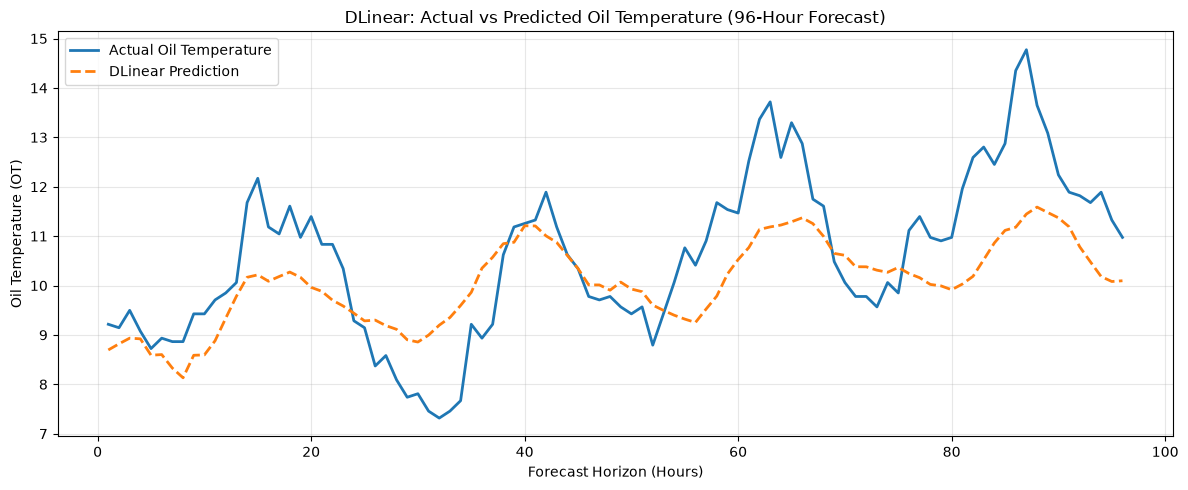

Figure saved to figures/05_DLinear_96h_Forecast.png


In [20]:
# Step 17B: Visualize DLinear 96-hour forecasts

# Select one test sample
sample_idx = 0

X_sample = X_test[sample_idx:sample_idx + 1].to(training_device)
y_actual = y_test[sample_idx].cpu().numpy()

# Generate prediction
model.eval()

with torch.no_grad():
    y_pred = model(X_sample).squeeze(0).cpu().numpy()

# Convert standardized OT values back to original temperature scale
y_actual_original = y_actual * ot_std + ot_mean
y_pred_original = y_pred * ot_std + ot_mean

# Forecast horizon
hours = np.arange(1, pred_len + 1)

plt.figure(figsize=(12, 5))

plt.plot(
    hours,
    y_actual_original,
    label="Actual Oil Temperature",
    linewidth=2
)

plt.plot(
    hours,
    y_pred_original,
    label="DLinear Prediction",
    linestyle="--",
    linewidth=2
)

plt.title("DLinear: Actual vs Predicted Oil Temperature (96-Hour Forecast)")
plt.xlabel("Forecast Horizon (Hours)")
plt.ylabel("Oil Temperature (OT)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    figures_dir / "05_DLinear_96h_Forecast.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to figures/05_DLinear_96h_Forecast.png")

In [21]:
# Step 18: Save DLinear evaluation results

import pandas as pd
from pathlib import Path

results_dir = Path("results")
results_dir.mkdir(exist_ok=True)

dlinear_results = pd.DataFrame([{
    "Model": "DLinear",
    "Input_Length": 96,
    "Prediction_Length": 96,
    "Validation_MSE": dlinear_val_mse,
    "Validation_MAE": dlinear_val_mae,
    "Test_MSE": dlinear_test_mse,
    "Test_MAE": dlinear_test_mae,
    "Best_Epoch": int(np.argmin(val_losses) + 1),
    "Epochs_Trained": len(train_losses),
    "Learning_Rate": learning_rate,
    "Parameters": sum(p.numel() for p in model.parameters()),
    "Training_Time_Seconds": 6.24
}])

results_path = results_dir / "DLinear_ETTh1_results.csv"

dlinear_results.to_csv(results_path, index=False)

print(dlinear_results.to_string(index=False))
print(f"\nResults saved to: {results_path}")

  Model  Input_Length  Prediction_Length  Validation_MSE  Validation_MAE  Test_MSE  Test_MAE  Best_Epoch  Epochs_Trained  Learning_Rate  Parameters  Training_Time_Seconds
DLinear            96                 96        0.096711        0.243047  0.071206  0.197362           2               7          0.001       18624                   6.24

Results saved to: results/DLinear_ETTh1_results.csv


In [23]:
# Step 21A: Retrieve model configuration

input_len = int(data["input_len"])
pred_len = int(data["pred_len"])
target_index = int(data["target_index"])
num_features = len(data["feature_cols"])

print("Input length:", input_len)
print("Prediction length:", pred_len)
print("Number of features:", num_features)
print("Target index:", target_index)

Input length: 96
Prediction length: 96
Number of features: 7
Target index: 6


In [27]:
# Step 21: Initialize DLinear Experiment 2

# Set random seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Create a fresh DLinear model
model_exp2 = DLinear(
    input_len=input_len,
    pred_len=pred_len,
    target_index=target_index,
    kernel_size=25
).to(training_device)

# Learning rate for Experiment 2
learning_rate_exp2 = 0.0001

# Create a fresh optimizer
optimizer_exp2 = optim.Adam(
    model_exp2.parameters(),
    lr=learning_rate_exp2
)

print("Experiment 2 initialized successfully!")
print("Learning rate:", learning_rate_exp2)
print("Device:", next(model_exp2.parameters()).device)
print(
    "Trainable parameters:",
    sum(p.numel() for p in model_exp2.parameters())
)

Experiment 2 initialized successfully!
Learning rate: 0.0001
Device: cuda:0
Trainable parameters: 18624


In [28]:
# Step 22: Inspect the existing training function

import inspect

print(inspect.getsource(train_dlinear))

def train_dlinear(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    device,
    num_epochs=30,
    patience=5
):

    os.makedirs("saved_models", exist_ok=True)

    checkpoint_path = "saved_models/DLinear_ETTh1_best.pt"

    train_losses = []
    val_losses = []

    best_val_loss = float("inf")
    epochs_without_improvement = 0

    start_time = time.time()

    for epoch in range(num_epochs):

        # Train for one epoch
        train_loss = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
            device
        )

        # Evaluate on validation data
        val_loss = validate_one_epoch(
            model,
            val_loader,
            criterion,
            device
        )

        # Save loss history
        train_losses.append(train_loss)
        val_losses.append(val_loss)

        print(
            f"Epoch [{epoch+1}/{num_epochs}] "
            f"Train MSE: {train_loss:.6f

In [32]:
# Step 23: Train DLinear Experiment 2

checkpoint_exp2 = "saved_models/DLinear_ETTh1_lr0.0001_run2.pt"

train_losses_exp2, val_losses_exp2, best_val_loss_exp2 = train_dlinear(
    model=model_exp2,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer_exp2,
    device=training_device,
    num_epochs=30,
    patience=5,
    checkpoint_path=checkpoint_exp2
)

print("\nExperiment 2 completed!")
print(f"Best validation MSE: {best_val_loss_exp2:.6f}")

Epoch [1/30] Train MSE: 0.187763 | Val MSE: 0.105853
  Best model saved!
Epoch [2/30] Train MSE: 0.174472 | Val MSE: 0.101979
  Best model saved!
Epoch [3/30] Train MSE: 0.169654 | Val MSE: 0.100130
  Best model saved!
Epoch [4/30] Train MSE: 0.167028 | Val MSE: 0.099141
  Best model saved!
Epoch [5/30] Train MSE: 0.165326 | Val MSE: 0.098593
  Best model saved!
Epoch [6/30] Train MSE: 0.164166 | Val MSE: 0.098097
  Best model saved!
Epoch [7/30] Train MSE: 0.163405 | Val MSE: 0.097626
  Best model saved!
Epoch [8/30] Train MSE: 0.162662 | Val MSE: 0.097577
  Best model saved!
Epoch [9/30] Train MSE: 0.162017 | Val MSE: 0.097491
  Best model saved!
Epoch [10/30] Train MSE: 0.161724 | Val MSE: 0.097129
  Best model saved!
Epoch [11/30] Train MSE: 0.161458 | Val MSE: 0.096808
  Best model saved!
Epoch [12/30] Train MSE: 0.161286 | Val MSE: 0.096878
Epoch [13/30] Train MSE: 0.160969 | Val MSE: 0.096884
Epoch [14/30] Train MSE: 0.160762 | Val MSE: 0.096690
  Best model saved!
Epoch [15/30]

In [33]:
# Step 24: Load the best DLinear Experiment 2 checkpoint

model_exp2.load_state_dict(
    torch.load(
        "saved_models/DLinear_ETTh1_lr0.0001_run2.pt",
        map_location=training_device,
        weights_only=True
    )
)

model_exp2.eval()

print("Experiment 2 best checkpoint loaded successfully!")
print("Device:", next(model_exp2.parameters()).device)

Experiment 2 best checkpoint loaded successfully!
Device: cuda:0


In [34]:
# Step 25: Evaluate DLinear Experiment 2

# Validation metrics
dlinear_val_mse_exp2, dlinear_val_mae_exp2 = evaluate_dlinear(
    model_exp2,
    val_loader,
    training_device
)

# Test metrics
dlinear_test_mse_exp2, dlinear_test_mae_exp2 = evaluate_dlinear(
    model_exp2,
    test_loader,
    training_device
)

print("DLinear Experiment 2 Evaluation Results")
print("-" * 40)

print(f"Validation MSE: {dlinear_val_mse_exp2:.6f}")
print(f"Validation MAE: {dlinear_val_mae_exp2:.6f}")
print(f"Test MSE:       {dlinear_test_mse_exp2:.6f}")
print(f"Test MAE:       {dlinear_test_mae_exp2:.6f}")

DLinear Experiment 2 Evaluation Results
----------------------------------------
Validation MSE: 0.096491
Validation MAE: 0.242729
Test MSE:       0.064651
Test MAE:       0.187502


In [35]:
# Step 26: Save DLinear Experiment 2 results

import pandas as pd
from pathlib import Path

results_dir = Path("results")
results_dir.mkdir(exist_ok=True)

dlinear_exp2_results = pd.DataFrame([{
    "Model": "DLinear",
    "Experiment": 2,
    "Input_Length": input_len,
    "Prediction_Length": pred_len,
    "Validation_MSE": dlinear_val_mse_exp2,
    "Validation_MAE": dlinear_val_mae_exp2,
    "Test_MSE": dlinear_test_mse_exp2,
    "Test_MAE": dlinear_test_mae_exp2,
    "Best_Epoch": int(np.argmin(val_losses_exp2) + 1),
    "Epochs_Trained": len(train_losses_exp2),
    "Learning_Rate": learning_rate_exp2,
    "Parameters": sum(
        p.numel() for p in model_exp2.parameters()
    ),
    "Checkpoint": checkpoint_exp2
}])

results_path_exp2 = results_dir / "DLinear_ETTh1_lr0.0001_run2_results.csv"

dlinear_exp2_results.to_csv(results_path_exp2, index=False)

print(dlinear_exp2_results.to_string(index=False))
print(f"\nResults saved to: {results_path_exp2}")

  Model  Experiment  Input_Length  Prediction_Length  Validation_MSE  Validation_MAE  Test_MSE  Test_MAE  Best_Epoch  Epochs_Trained  Learning_Rate  Parameters                                  Checkpoint
DLinear           2            96                 96        0.096491        0.242729  0.064651  0.187502          18              23         0.0001       18624 saved_models/DLinear_ETTh1_lr0.0001_run2.pt

Results saved to: results/DLinear_ETTh1_lr0.0001_run2_results.csv


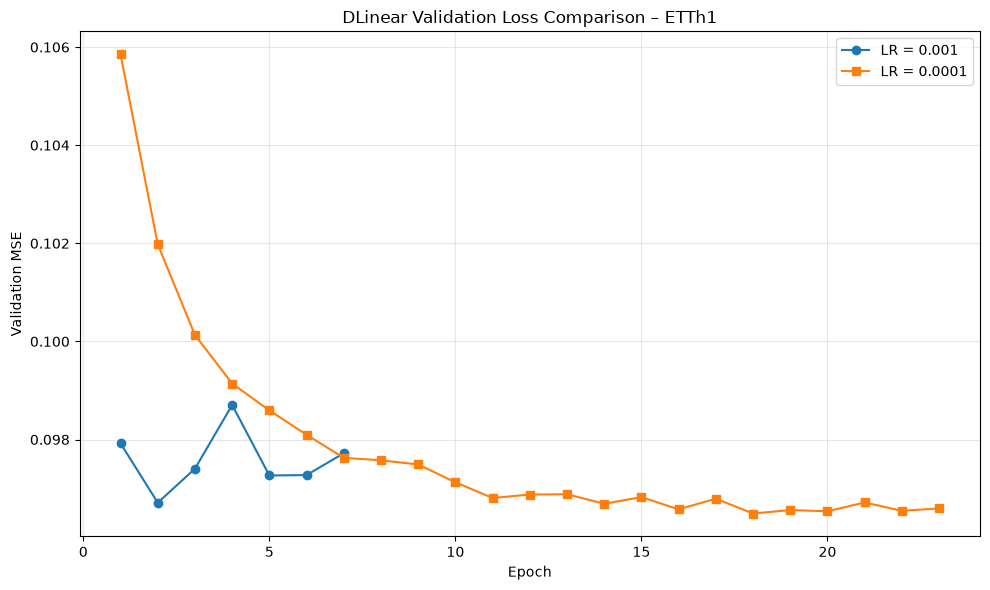

Experiment 1 best validation MSE: 0.096711
Experiment 2 best validation MSE: 0.096491
Figure saved successfully!


In [36]:
# Step 27: Compare DLinear learning rates

from pathlib import Path

figures_dir = Path("figures")
figures_dir.mkdir(exist_ok=True)

plt.figure(figsize=(10, 6))

plt.plot(
    range(1, len(val_losses) + 1),
    val_losses,
    marker="o",
    label="LR = 0.001"
)

plt.plot(
    range(1, len(val_losses_exp2) + 1),
    val_losses_exp2,
    marker="s",
    label="LR = 0.0001"
)

plt.xlabel("Epoch")
plt.ylabel("Validation MSE")
plt.title("DLinear Validation Loss Comparison – ETTh1")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    figures_dir / "06_DLinear_Learning_Rate_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Experiment 1 best validation MSE:", round(min(val_losses), 6))
print("Experiment 2 best validation MSE:", round(min(val_losses_exp2), 6))
print("Figure saved successfully!")

## 9. Extended DLinear Forecasting: 336 and 720 Hours

This section extends DLinear forecasting to 336-hour and 720-hour
prediction horizons, keeping the historical input length at 96 hours.

We use the same chronological data splits, preprocessing method,
and evaluation metrics as the 96-hour experiments.

Separate models and checkpoints are used for each horizon.

In [37]:
# Step 28: Load the 336-hour forecasting dataset

import torch
from pathlib import Path

data_336 = torch.load(
    Path("processed_data/ETTh1_336h_preprocessed.pt"),
    map_location="cpu",
    weights_only=True
)

print("336-hour dataset loaded successfully!")
print("-" * 40)

print("Input length:", data_336["input_len"])
print("Prediction length:", data_336["pred_len"])
print("Target index:", data_336["target_index"])

print("\nTraining inputs:", tuple(data_336["X_train"].shape))
print("Training targets:", tuple(data_336["y_train"].shape))

print("\nValidation inputs:", tuple(data_336["X_val"].shape))
print("Validation targets:", tuple(data_336["y_val"].shape))

print("\nTesting inputs:", tuple(data_336["X_test"].shape))
print("Testing targets:", tuple(data_336["y_test"].shape))

336-hour dataset loaded successfully!
----------------------------------------
Input length: 96
Prediction length: 336
Target index: 6

Training inputs: (8209, 96, 7)
Training targets: (8209, 336)

Validation inputs: (2545, 96, 7)
Validation targets: (2545, 336)

Testing inputs: (2545, 96, 7)
Testing targets: (2545, 336)


In [38]:
# Step 29: Create DataLoaders for 336-hour DLinear forecasting

from torch.utils.data import TensorDataset, DataLoader

# Create PyTorch datasets
train_dataset_336 = TensorDataset(
    data_336["X_train"],
    data_336["y_train"]
)

val_dataset_336 = TensorDataset(
    data_336["X_val"],
    data_336["y_val"]
)

test_dataset_336 = TensorDataset(
    data_336["X_test"],
    data_336["y_test"]
)

# Create DataLoaders
batch_size_336 = 32

train_loader_336 = DataLoader(
    train_dataset_336,
    batch_size=batch_size_336,
    shuffle=True
)

val_loader_336 = DataLoader(
    val_dataset_336,
    batch_size=batch_size_336,
    shuffle=False
)

test_loader_336 = DataLoader(
    test_dataset_336,
    batch_size=batch_size_336,
    shuffle=False
)

# Verify batch dimensions
X_batch_336, y_batch_336 = next(iter(train_loader_336))

print("336-hour DataLoaders created successfully!")
print("-" * 45)
print("Training batches:", len(train_loader_336))
print("Validation batches:", len(val_loader_336))
print("Testing batches:", len(test_loader_336))

print("\nInput batch shape:", tuple(X_batch_336.shape))
print("Target batch shape:", tuple(y_batch_336.shape))

336-hour DataLoaders created successfully!
---------------------------------------------
Training batches: 257
Validation batches: 80
Testing batches: 80

Input batch shape: (32, 96, 7)
Target batch shape: (32, 336)


In [39]:
# Step 30: Initialize DLinear for 336-hour forecasting

import torch

# Set random seed for reproducibility
torch.manual_seed(42)
torch.cuda.manual_seed_all(42)

# Select GPU if available
device_336 = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)

# Initialize DLinear model
model_336 = DLinear(
    input_len=96,
    pred_len=336,
    target_index=6,
    kernel_size=25
).to(device_336)

# Count trainable parameters
params_336 = sum(
    p.numel()
    for p in model_336.parameters()
    if p.requires_grad
)

# Verify model output
model_336.eval()

with torch.no_grad():
    sample_output_336 = model_336(
        X_batch_336.to(device_336)
    )

print("336-hour DLinear model initialized successfully!")
print("-" * 50)
print("Device:", device_336)
print("Input length:", 96)
print("Prediction length:", 336)
print("Trainable parameters:", f"{params_336:,}")
print("Input shape:", tuple(X_batch_336.shape))
print("Output shape:", tuple(sample_output_336.shape))

336-hour DLinear model initialized successfully!
--------------------------------------------------
Device: cuda:0
Input length: 96
Prediction length: 336
Trainable parameters: 65,184
Input shape: (32, 96, 7)
Output shape: (32, 336)


In [40]:
# Step 31: Configure training for 336-hour DLinear

import torch.nn as nn
import torch.optim as optim
from pathlib import Path

# Learning rate selected from our 96-hour experiments
learning_rate_336 = 0.0001

# Loss function: Mean Squared Error
criterion_336 = nn.MSELoss()

# Adam optimizer
optimizer_336 = optim.Adam(
    model_336.parameters(),
    lr=learning_rate_336
)

# Training configuration
max_epochs_336 = 30
patience_336 = 5

# Separate checkpoint to protect the 96-hour model
checkpoint_path_336 = Path(
    "saved_models/DLinear_ETTh1_336h_best.pt"
)

checkpoint_path_336.parent.mkdir(
    parents=True,
    exist_ok=True
)

print("336-hour training configuration ready!")
print("-" * 45)
print("Optimizer: Adam")
print("Learning rate:", learning_rate_336)
print("Loss function: MSE")
print("Maximum epochs:", max_epochs_336)
print("Early stopping patience:", patience_336)
print("Checkpoint:", checkpoint_path_336)

336-hour training configuration ready!
---------------------------------------------
Optimizer: Adam
Learning rate: 0.0001
Loss function: MSE
Maximum epochs: 30
Early stopping patience: 5
Checkpoint: saved_models/DLinear_ETTh1_336h_best.pt


In [41]:
# Step 32: Train the 336-hour DLinear model

import inspect

# Check the existing training function's parameters
print("Training function signature:")
print(inspect.signature(train_dlinear))

Training function signature:
(model, train_loader, val_loader, criterion, optimizer, device, num_epochs=30, patience=5, checkpoint_path='saved_models/DLinear_ETTh1_best.pt')


In [42]:
# Step 33: Train the 336-hour DLinear model

history_336 = train_dlinear(
    model=model_336,
    train_loader=train_loader_336,
    val_loader=val_loader_336,
    criterion=criterion_336,
    optimizer=optimizer_336,
    device=device_336,
    num_epochs=max_epochs_336,
    patience=patience_336,
    checkpoint_path=str(checkpoint_path_336)
)

Epoch [1/30] Train MSE: 0.222019 | Val MSE: 0.136892
  Best model saved!
Epoch [2/30] Train MSE: 0.213169 | Val MSE: 0.133394
  Best model saved!
Epoch [3/30] Train MSE: 0.210292 | Val MSE: 0.131541
  Best model saved!
Epoch [4/30] Train MSE: 0.208828 | Val MSE: 0.130973
  Best model saved!
Epoch [5/30] Train MSE: 0.207985 | Val MSE: 0.130120
  Best model saved!
Epoch [6/30] Train MSE: 0.207501 | Val MSE: 0.129885
  Best model saved!
Epoch [7/30] Train MSE: 0.207013 | Val MSE: 0.129395
  Best model saved!
Epoch [8/30] Train MSE: 0.206715 | Val MSE: 0.129463
Epoch [9/30] Train MSE: 0.206606 | Val MSE: 0.129330
  Best model saved!
Epoch [10/30] Train MSE: 0.206218 | Val MSE: 0.129020
  Best model saved!
Epoch [11/30] Train MSE: 0.206169 | Val MSE: 0.128935
  Best model saved!
Epoch [12/30] Train MSE: 0.206019 | Val MSE: 0.129283
Epoch [13/30] Train MSE: 0.205814 | Val MSE: 0.128641
  Best model saved!
Epoch [14/30] Train MSE: 0.205698 | Val MSE: 0.129361
Epoch [15/30] Train MSE: 0.205823

In [43]:
# Step 34: Check the DLinear evaluation function

import inspect

print("Evaluation function signature:")
print(inspect.signature(evaluate_dlinear))

print("\n336-hour checkpoint exists:")
print(checkpoint_path_336.exists())

Evaluation function signature:
(model, data_loader, device)

336-hour checkpoint exists:
True


In [44]:
# Step 35: Evaluate the best 336-hour DLinear model

import torch

# Load the best model weights
model_336.load_state_dict(
    torch.load(
        checkpoint_path_336,
        map_location=device_336,
        weights_only=True
    )
)

# Set the model to evaluation mode
model_336.eval()

# Evaluate validation and test datasets
val_mse_336, val_mae_336 = evaluate_dlinear(
    model_336,
    val_loader_336,
    device_336
)

test_mse_336, test_mae_336 = evaluate_dlinear(
    model_336,
    test_loader_336,
    device_336
)

# Display results
print("DLinear 336-hour Evaluation Results")
print("-" * 45)

print(f"Validation MSE: {val_mse_336:.6f}")
print(f"Validation MAE: {val_mae_336:.6f}")

print(f"\nTest MSE: {test_mse_336:.6f}")
print(f"Test MAE: {test_mae_336:.6f}")

DLinear 336-hour Evaluation Results
---------------------------------------------
Validation MSE: 0.128641
Validation MAE: 0.286215

Test MSE: 0.095971
Test MAE: 0.240374


In [45]:
# Step 36: Save DLinear 336-hour evaluation results

import pandas as pd
from pathlib import Path

results_dir = Path("results")
results_dir.mkdir(parents=True, exist_ok=True)

dlinear_336_results = pd.DataFrame([{
    "model": "DLinear",
    "input_len": 96,
    "pred_len": 336,
    "learning_rate": learning_rate_336,
    "parameters": params_336,
    "val_mse": val_mse_336,
    "val_mae": val_mae_336,
    "test_mse": test_mse_336,
    "test_mae": test_mae_336
}])

results_path_336 = results_dir / "DLinear_ETTh1_336h_results.csv"

dlinear_336_results.to_csv(
    results_path_336,
    index=False
)

print("336-hour DLinear results saved successfully!")
print("File:", results_path_336)

display(dlinear_336_results)

336-hour DLinear results saved successfully!
File: results/DLinear_ETTh1_336h_results.csv


,model,input_len,pred_len,learning_rate,parameters,val_mse,val_mae,test_mse,test_mae
0,DLinear,96,336,0.0001,65184,0.128641,0.286215,0.095971,0.240374


### 9.2 DLinear Forecasting: 720-Hour Prediction Horizon

This experiment evaluates DLinear for a 720-hour (30-day)
forecasting horizon using 96 hours of historical observations.

We maintain the same preprocessing approach, model architecture,
learning rate, and training strategy used for the 336-hour experiment.

In [46]:
# Step 37: Load the 720-hour forecasting dataset

from pathlib import Path
import torch

data_720 = torch.load(
    Path("processed_data/ETTh1_720h_preprocessed.pt"),
    map_location="cpu",
    weights_only=True
)

print("720-hour dataset loaded successfully!")
print("-" * 45)

print("Input length:", data_720["input_len"])
print("Prediction length:", data_720["pred_len"])
print("Target index:", data_720["target_index"])

print("\nTraining inputs:", tuple(data_720["X_train"].shape))
print("Training targets:", tuple(data_720["y_train"].shape))

print("\nValidation inputs:", tuple(data_720["X_val"].shape))
print("Validation targets:", tuple(data_720["y_val"].shape))

print("\nTesting inputs:", tuple(data_720["X_test"].shape))
print("Testing targets:", tuple(data_720["y_test"].shape))

720-hour dataset loaded successfully!
---------------------------------------------
Input length: 96
Prediction length: 720
Target index: 6

Training inputs: (7825, 96, 7)
Training targets: (7825, 720)

Validation inputs: (2161, 96, 7)
Validation targets: (2161, 720)

Testing inputs: (2161, 96, 7)
Testing targets: (2161, 720)


In [47]:
# Step 38: Create DataLoaders for 720-hour DLinear forecasting

from torch.utils.data import TensorDataset, DataLoader

# Create PyTorch datasets
train_dataset_720 = TensorDataset(
    data_720["X_train"],
    data_720["y_train"]
)

val_dataset_720 = TensorDataset(
    data_720["X_val"],
    data_720["y_val"]
)

test_dataset_720 = TensorDataset(
    data_720["X_test"],
    data_720["y_test"]
)

# Keep the same batch size as previous experiments
batch_size_720 = 32

# Create DataLoaders
train_loader_720 = DataLoader(
    train_dataset_720,
    batch_size=batch_size_720,
    shuffle=True
)

val_loader_720 = DataLoader(
    val_dataset_720,
    batch_size=batch_size_720,
    shuffle=False
)

test_loader_720 = DataLoader(
    test_dataset_720,
    batch_size=batch_size_720,
    shuffle=False
)

# Verify batch dimensions
X_batch_720, y_batch_720 = next(iter(train_loader_720))

print("720-hour DataLoaders created successfully!")
print("-" * 45)

print("Training batches:", len(train_loader_720))
print("Validation batches:", len(val_loader_720))
print("Testing batches:", len(test_loader_720))

print("\nInput batch shape:", tuple(X_batch_720.shape))
print("Target batch shape:", tuple(y_batch_720.shape))

720-hour DataLoaders created successfully!
---------------------------------------------
Training batches: 245
Validation batches: 68
Testing batches: 68

Input batch shape: (32, 96, 7)
Target batch shape: (32, 720)


In [48]:
# Step 39: Initialize DLinear for 720-hour forecasting

import torch

# Set random seed for reproducibility
torch.manual_seed(42)
torch.cuda.manual_seed_all(42)

# Select GPU if available
device_720 = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)

# Initialize the 720-hour DLinear model
model_720 = DLinear(
    input_len=96,
    pred_len=720,
    target_index=6,
    kernel_size=25
).to(device_720)

# Count trainable parameters
params_720 = sum(
    p.numel()
    for p in model_720.parameters()
    if p.requires_grad
)

# Check the output dimensions
model_720.eval()

with torch.no_grad():
    sample_output_720 = model_720(
        X_batch_720.to(device_720)
    )

print("720-hour DLinear model initialized successfully!")
print("-" * 50)
print("Device:", device_720)
print("Input length:", 96)
print("Prediction length:", 720)
print("Trainable parameters:", f"{params_720:,}")
print("Input shape:", tuple(X_batch_720.shape))
print("Output shape:", tuple(sample_output_720.shape))

720-hour DLinear model initialized successfully!
--------------------------------------------------
Device: cuda:0
Input length: 96
Prediction length: 720
Trainable parameters: 139,680
Input shape: (32, 96, 7)
Output shape: (32, 720)


In [49]:
# Step 40: Configure training for 720-hour DLinear

import torch.nn as nn
import torch.optim as optim
from pathlib import Path

# Learning rate
learning_rate_720 = 0.0001

# Loss function
criterion_720 = nn.MSELoss()

# Adam optimizer
optimizer_720 = optim.Adam(
    model_720.parameters(),
    lr=learning_rate_720
)

# Training configuration
max_epochs_720 = 30
patience_720 = 5

# Separate checkpoint for the 720-hour model
checkpoint_path_720 = Path(
    "saved_models/DLinear_ETTh1_720h_best.pt"
)

checkpoint_path_720.parent.mkdir(
    parents=True,
    exist_ok=True
)

print("720-hour training configuration ready!")
print("-" * 45)
print("Optimizer: Adam")
print("Learning rate:", learning_rate_720)
print("Loss function: MSE")
print("Maximum epochs:", max_epochs_720)
print("Early stopping patience:", patience_720)
print("Checkpoint:", checkpoint_path_720)

720-hour training configuration ready!
---------------------------------------------
Optimizer: Adam
Learning rate: 0.0001
Loss function: MSE
Maximum epochs: 30
Early stopping patience: 5
Checkpoint: saved_models/DLinear_ETTh1_720h_best.pt


In [50]:
# Step 41: Train the 720-hour DLinear model

history_720 = train_dlinear(
    model=model_720,
    train_loader=train_loader_720,
    val_loader=val_loader_720,
    criterion=criterion_720,
    optimizer=optimizer_720,
    device=device_720,
    num_epochs=max_epochs_720,
    patience=patience_720,
    checkpoint_path=str(checkpoint_path_720)
)

Epoch [1/30] Train MSE: 0.266836 | Val MSE: 0.181966
  Best model saved!
Epoch [2/30] Train MSE: 0.254085 | Val MSE: 0.172552
  Best model saved!
Epoch [3/30] Train MSE: 0.249910 | Val MSE: 0.166894
  Best model saved!
Epoch [4/30] Train MSE: 0.247797 | Val MSE: 0.163800
  Best model saved!
Epoch [5/30] Train MSE: 0.246552 | Val MSE: 0.161647
  Best model saved!
Epoch [6/30] Train MSE: 0.245767 | Val MSE: 0.159809
  Best model saved!
Epoch [7/30] Train MSE: 0.245306 | Val MSE: 0.158917
  Best model saved!
Epoch [8/30] Train MSE: 0.244984 | Val MSE: 0.158078
  Best model saved!
Epoch [9/30] Train MSE: 0.244670 | Val MSE: 0.158271
Epoch [10/30] Train MSE: 0.244458 | Val MSE: 0.157717
  Best model saved!
Epoch [11/30] Train MSE: 0.244559 | Val MSE: 0.156970
  Best model saved!
Epoch [12/30] Train MSE: 0.244429 | Val MSE: 0.157138
Epoch [13/30] Train MSE: 0.244178 | Val MSE: 0.157002
Epoch [14/30] Train MSE: 0.243997 | Val MSE: 0.157814
Epoch [15/30] Train MSE: 0.244177 | Val MSE: 0.156964

In [51]:
# Step 42: Evaluate the best 720-hour DLinear model

import torch

# Load the best saved model weights
model_720.load_state_dict(
    torch.load(
        checkpoint_path_720,
        map_location=device_720,
        weights_only=True
    )
)

# Switch to evaluation mode
model_720.eval()

# Evaluate on validation and test datasets
val_mse_720, val_mae_720 = evaluate_dlinear(
    model_720,
    val_loader_720,
    device_720
)

test_mse_720, test_mae_720 = evaluate_dlinear(
    model_720,
    test_loader_720,
    device_720
)

# Display results
print("DLinear 720-hour Evaluation Results")
print("-" * 45)

print(f"Validation MSE: {val_mse_720:.6f}")
print(f"Validation MAE: {val_mae_720:.6f}")

print(f"\nTest MSE: {test_mse_720:.6f}")
print(f"Test MAE: {test_mae_720:.6f}")

DLinear 720-hour Evaluation Results
---------------------------------------------
Validation MSE: 0.156942
Validation MAE: 0.316475

Test MSE: 0.167763
Test MAE: 0.335462


In [52]:
# Step 43: Save DLinear 720-hour evaluation results

import pandas as pd
from pathlib import Path

results_dir = Path("results")
results_dir.mkdir(parents=True, exist_ok=True)

dlinear_720_results = pd.DataFrame([{
    "model": "DLinear",
    "input_len": 96,
    "pred_len": 720,
    "learning_rate": learning_rate_720,
    "parameters": params_720,
    "val_mse": val_mse_720,
    "val_mae": val_mae_720,
    "test_mse": test_mse_720,
    "test_mae": test_mae_720
}])

results_path_720 = results_dir / "DLinear_ETTh1_720h_results.csv"

dlinear_720_results.to_csv(
    results_path_720,
    index=False
)

print("720-hour DLinear results saved successfully!")
print("File:", results_path_720)

display(dlinear_720_results)

720-hour DLinear results saved successfully!
File: results/DLinear_ETTh1_720h_results.csv


,model,input_len,pred_len,learning_rate,parameters,val_mse,val_mae,test_mse,test_mae
0,DLinear,96,720,0.0001,139680,0.156942,0.316475,0.167763,0.335462


In [55]:
# Step 44A: Inspect the columns in the results files

print("Persistence columns:")
print(persistence_results.columns.tolist())

print("\nDLinear 96h columns:")
print(dlinear_96_results.columns.tolist())

print("\nDLinear 96h data:")
display(dlinear_96_results)

print("\nDLinear 336h columns:")
print(dlinear_336_results.columns.tolist())

print("\nDLinear 720h columns:")
print(dlinear_720_results.columns.tolist())

Persistence columns:
['model', 'input_len', 'pred_len', 'val_mse', 'val_mae', 'test_mse', 'test_mae']

DLinear 96h columns:
['Model', 'Experiment', 'Input_Length', 'Prediction_Length', 'Validation_MSE', 'Validation_MAE', 'Test_MSE', 'Test_MAE', 'Best_Epoch', 'Epochs_Trained', 'Learning_Rate', 'Parameters', 'Checkpoint']

DLinear 96h data:


,Model,Experiment,Input_Length,Prediction_Length,Validation_MSE,Validation_MAE,Test_MSE,Test_MAE,Best_Epoch,Epochs_Trained,Learning_Rate,Parameters,Checkpoint
0,DLinear,2,96,96,0.096491,0.242729,0.064651,0.187502,18,23,0.0001,18624,saved_models/DLinear_ETTh1_lr0.0001_run2.pt



DLinear 336h columns:
['model', 'input_len', 'pred_len', 'learning_rate', 'parameters', 'val_mse', 'val_mae', 'test_mse', 'test_mae']

DLinear 720h columns:
['model', 'input_len', 'pred_len', 'learning_rate', 'parameters', 'val_mse', 'val_mae', 'test_mse', 'test_mae']


In [56]:
# Step 44B: Consolidate Persistence and DLinear results

import pandas as pd
from pathlib import Path

results_dir = Path("results")

# Load results from saved CSV files
persistence_results = pd.read_csv(
    results_dir / "Persistence_All_Horizons.csv"
)

dlinear_96_results = pd.read_csv(
    results_dir / "DLinear_ETTh1_lr0.0001_run2_results.csv"
)

dlinear_336_results = pd.read_csv(
    results_dir / "DLinear_ETTh1_336h_results.csv"
)

dlinear_720_results = pd.read_csv(
    results_dir / "DLinear_ETTh1_720h_results.csv"
)

# Rename the 96-hour DLinear columns to match other results
dlinear_96_results = dlinear_96_results.rename(columns={
    "Model": "model",
    "Input_Length": "input_len",
    "Prediction_Length": "pred_len",
    "Validation_MSE": "val_mse",
    "Validation_MAE": "val_mae",
    "Test_MSE": "test_mse",
    "Test_MAE": "test_mae"
})

# Select common columns
comparison_columns = [
    "model",
    "input_len",
    "pred_len",
    "val_mse",
    "val_mae",
    "test_mse",
    "test_mae"
]

# Combine all results
comparison_results = pd.concat(
    [
        persistence_results[comparison_columns],
        dlinear_96_results[comparison_columns],
        dlinear_336_results[comparison_columns],
        dlinear_720_results[comparison_columns]
    ],
    ignore_index=True
)

# Sort by prediction horizon and model
comparison_results = comparison_results.sort_values(
    by=["pred_len", "model"]
).reset_index(drop=True)

# Save consolidated comparison
comparison_path = results_dir / "Forecasting_Model_Comparison.csv"

comparison_results.to_csv(
    comparison_path,
    index=False
)

print("Consolidated comparison saved successfully!")
print("File:", comparison_path)
print("Total experiments:", len(comparison_results))

display(comparison_results.round(6))

Consolidated comparison saved successfully!
File: results/Forecasting_Model_Comparison.csv
Total experiments: 6


,model,input_len,pred_len,val_mse,val_mae,test_mse,test_mae
0,DLinear,96,96,0.096491,0.242729,0.064651,0.187502
1,Persistence,96,96,0.137300,0.283200,0.069300,0.203300
2,DLinear,96,336,0.128641,0.286215,0.095971,0.240374
3,Persistence,96,336,0.185977,0.340134,0.113274,0.265204
4,DLinear,96,720,0.156942,0.316475,0.167763,0.335462
5,Persistence,96,720,0.248023,0.396071,0.129179,0.283409


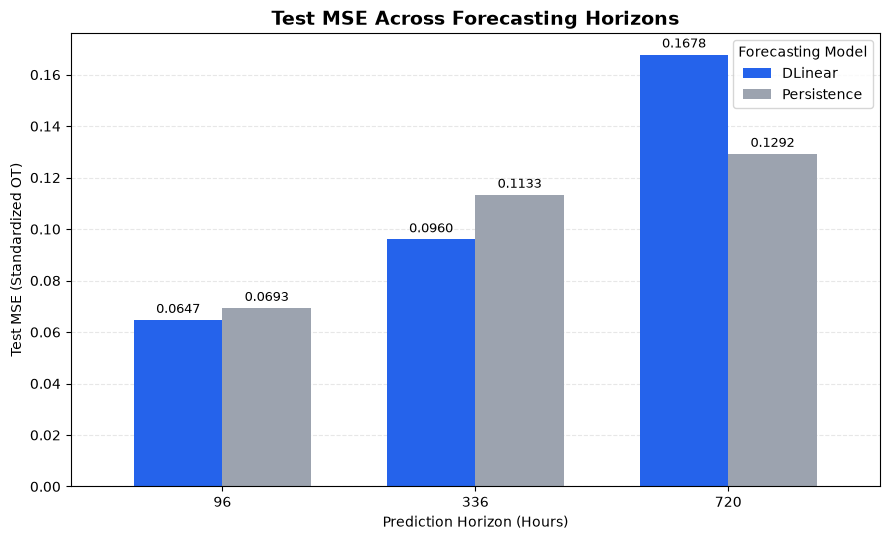

Figure saved successfully!
File: figures/07_Test_MSE_Model_Comparison.png


In [57]:
# Step 45: Plot test MSE across forecasting horizons

import matplotlib.pyplot as plt
from pathlib import Path

# Prepare results for plotting
mse_comparison = comparison_results.pivot(
    index="pred_len",
    columns="model",
    values="test_mse"
).sort_index()

# Create figure
fig, ax = plt.subplots(figsize=(9, 5.5))

mse_comparison.plot(
    kind="bar",
    ax=ax,
    width=0.7,
    color={
        "Persistence": "#9CA3AF",
        "DLinear": "#2563EB"
    }
)

ax.set_title(
    "Test MSE Across Forecasting Horizons",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("Prediction Horizon (Hours)")
ax.set_ylabel("Test MSE (Standardized OT)")
ax.set_xticklabels(mse_comparison.index, rotation=0)

ax.legend(title="Forecasting Model")
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

# Add numerical labels above bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.4f", padding=3, fontsize=9)

plt.tight_layout()

# Save high-resolution figure
figures_dir = Path("figures")
figures_dir.mkdir(parents=True, exist_ok=True)

figure_path = figures_dir / "07_Test_MSE_Model_Comparison.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved successfully!")
print("File:", figure_path)

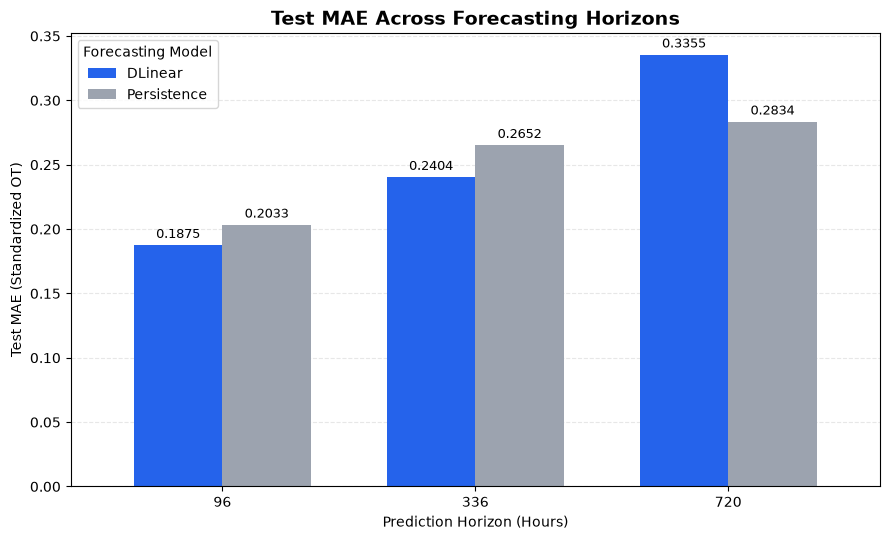

Figure saved successfully!
File: figures/08_Test_MAE_Model_Comparison.png


In [58]:
# Step 46: Plot test MAE across forecasting horizons

import matplotlib.pyplot as plt
from pathlib import Path

# Prepare results
mae_comparison = comparison_results.pivot(
    index="pred_len",
    columns="model",
    values="test_mae"
).sort_index()

# Create figure
fig, ax = plt.subplots(figsize=(9, 5.5))

mae_comparison.plot(
    kind="bar",
    ax=ax,
    width=0.7,
    color={
        "Persistence": "#9CA3AF",
        "DLinear": "#2563EB"
    }
)

ax.set_title(
    "Test MAE Across Forecasting Horizons",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Prediction Horizon (Hours)")
ax.set_ylabel("Test MAE (Standardized OT)")
ax.set_xticklabels(mae_comparison.index, rotation=0)

ax.legend(title="Forecasting Model")
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

# Add values above bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.4f", padding=3, fontsize=9)

plt.tight_layout()

# Save figure
figures_dir = Path("figures")
figures_dir.mkdir(parents=True, exist_ok=True)

figure_path = figures_dir / "08_Test_MAE_Model_Comparison.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved successfully!")
print("File:", figure_path)